
# Standalone MEK → ERK validation

**Goal:** test whether the existing bounded ODE framework can qualitatively reproduce the transient MEK/MAPK dynamics reported by Traverse et al. (1992) after EGF stimulation.

This notebook is deliberately **separate from the main Drug Diffusion model**. It is a validation experiment for the downstream signaling module only.

### What is being tested?

We use the same bounded activation/deactivation structure:

$$
\frac{dX^*}{dt}
=
k_{\mathrm{act}}U^*(X_{\mathrm{tot}}-X^*)
-
k_{\mathrm{deact}}X^*
$$

After normalization ($(X_{\mathrm{tot}}=1)$):

$$
\frac{dX}{dt}
=
k_{\mathrm{act}}U(t)(1-X)
-
k_{\mathrm{deact}}X
$$

For this reduced experiment:

- **MEK** represents the experimentally measured MAPKK activity.
- **ERK** represents the experimentally measured MAPK activity.
- A transient upstream drive \(u(t)\) represents the fact that EGF does not produce a permanently sustained MAPKK stimulus in the Traverse experiment.
- The parameters below are **qualitative trial values**, not claims about measured biochemical rate constants.

The purpose is to ask: **can this model structure produce the experimentally observed ordering and transient shape at all?**



## 1. Experimental data: Traverse et al. (1992)

The EGF experiment in Figure 1b reports MAPKK and MAP kinase activity over time in PC12 cells.

The values below are **manually digitized/approximated from the published graph and normalized to each curve's approximate peak**. They should therefore be treated as a visual comparison dataset, not as exact numerical measurements.

Important qualitative features reported in the paper:

- MAPKK activates very rapidly, with a peak at about **2 min**.
- MAP kinase activation is slightly slower, peaking at about **5 min**.
- MAPKK activity falls rapidly after its peak.
- MAP kinase activity remains elevated longer before declining toward baseline.

This is useful because the model must reproduce both the **temporal ordering** and the **different persistence** of the two signals.


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# Approximate, manually digitized values from Traverse et al. (1992), Fig. 1b.
# Normalized independently to the approximate peak of each experimental curve.

t_exp = np.array([0, 2, 5, 20, 60, 90], dtype=float)

mapkk_exp = np.array([
    0.02, 1.00, 0.63, 0.15, 0.10, 0.06
], dtype=float)

mapk_exp = np.array([
    0.02, 0.88, 1.00, 0.78, 0.26, 0.16
], dtype=float)


## 2. Reduced bounded ODE

We retain the same basic framework used in the main project, but isolate only the downstream signaling module:

\[
u(t)\rightarrow MEK\rightarrow ERK
\]

The transient upstream drive is modeled here as:

\[
u(t)=e^{-t/\tau_u}
\]

This is an **explicit modeling assumption for the validation test**, not an experimental measurement.

The important point is that we are not trying to force a transient ERK response by hand. The transient should emerge from the interaction between the upstream drive, MEK activation/deactivation, and ERK activation/deactivation.


In [35]:

def transient_input(t, tau_u):
    return np.exp(-t / tau_u)

def bounded_mek_erk_rhs(t, y, k_mek_act, k_mek_deact,
                        k_erk_act, k_erk_deact, tau_u):
    mek, erk = y
    u = transient_input(t, tau_u)

    dmek = k_mek_act * u * (1.0 - mek) - k_mek_deact * mek
    derk = k_erk_act * mek * (1.0 - erk) - k_erk_deact * erk

    return [dmek, derk]

# Qualitative trial parameter set.
# Units here are min^-1 because Traverse reports time in minutes.
params = {
    "k_mek_act": 2.0,
    "k_mek_deact": 0.15,
    "k_erk_act": 1.5,
    "k_erk_deact": 0.025,
    "tau_u": 2.0,
}

t_model = np.linspace(0, 90, 1801)

sol = solve_ivp(
    lambda t, y: bounded_mek_erk_rhs(
        t, y,
        params["k_mek_act"],
        params["k_mek_deact"],
        params["k_erk_act"],
        params["k_erk_deact"],
        params["tau_u"],
    ),
    (0, 90),
    [0.0, 0.0],
    t_eval=t_model,
    rtol=1e-9,
    atol=1e-12,
)

mek_model = sol.y[0]
erk_model = sol.y[1]

# Normalize each model trajectory to its own peak for shape comparison.
mek_model_norm = mek_model / mek_model.max()
erk_model_norm = erk_model / erk_model.max()

print("Trial parameters:")
for k, v in params.items():
    print(f"  {k} = {v}")

print("\nModel peak times:")
print(f"  MEK: {t_model[np.argmax(mek_model_norm)]:.2f} min")
print(f"  ERK: {t_model[np.argmax(erk_model_norm)]:.2f} min")


Trial parameters:
  k_mek_act = 2.0
  k_mek_deact = 0.15
  k_erk_act = 1.5
  k_erk_deact = 0.025
  tau_u = 2.0

Model peak times:
  MEK: 2.10 min
  ERK: 5.75 min


In [37]:
from scipy.optimize import least_squares


# ---------------------------------------------------------
# MEK/MAPKK parameter fitting
# ---------------------------------------------------------

def simulate_mek(params_mek):
    k_mek_act, k_mek_deact, tau_u = params_mek

    def rhs(t, y):
        mek = y[0]
        u = np.exp(-t / tau_u)

        dmek = (
            k_mek_act * u * (1.0 - mek)
            - k_mek_deact * mek
        )

        return [dmek]

    sol = solve_ivp(
        rhs,
        (t_exp.min(), t_exp.max()),
        [0.02],                 # approximate normalized baseline
        t_eval=t_exp,
        rtol=1e-9,
        atol=1e-12,
    )

    mek = sol.y[0]

    # Normalize model to its own peak,
    # matching how the experimental data were normalized.
    mek_norm = mek / mek.max()

    return mek_norm


def mek_residuals(params_mek):
    mek_model = simulate_mek(params_mek)

    return mek_model - mapkk_exp


# Initial guess from your current trial parameters
initial_guess = [
    2.0,    # k_mek_act
    0.15,   # k_mek_deact
    2.0     # tau_u
]

# Positive parameters only
lower_bounds = [1e-6, 1e-6, 0.05]
upper_bounds = [100.0, 10.0, 100.0]


fit_mek = least_squares(
    mek_residuals,
    initial_guess,
    bounds=(lower_bounds, upper_bounds),
    x_scale="jac"
)


k_mek_act_fit, k_mek_deact_fit, tau_u_fit = fit_mek.x

print("Fitted MEK parameters:")
print(f"  k_mek_act   = {k_mek_act_fit:.6f}")
print(f"  k_mek_deact = {k_mek_deact_fit:.6f}")
print(f"  tau_u       = {tau_u_fit:.6f}")

print("\nMEK fitting SSE:")
print(f"  {np.sum(fit_mek.fun**2):.6f}")

Fitted MEK parameters:
  k_mek_act   = 40.298894
  k_mek_deact = 0.129869
  tau_u       = 0.181967

MEK fitting SSE:
  0.018609


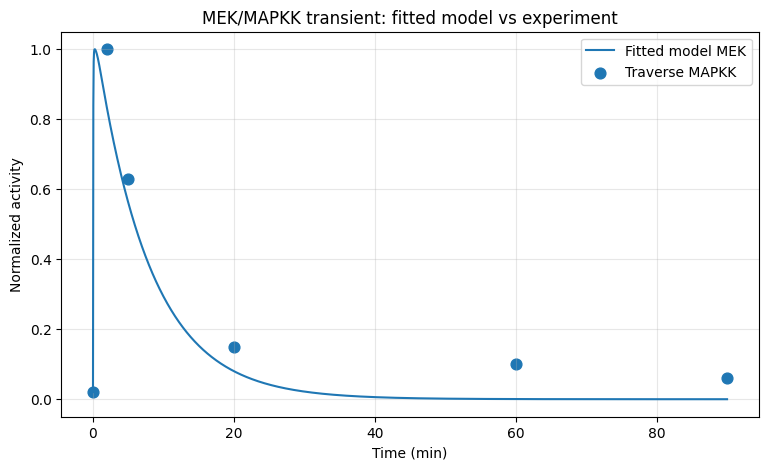

In [38]:
# Dense time grid for plotting
t_dense = np.linspace(0, 90, 1801)

def simulate_mek_dense(params_mek):
    k_mek_act, k_mek_deact, tau_u = params_mek

    def rhs(t, y):
        mek = y[0]
        u = np.exp(-t / tau_u)

        dmek = (
            k_mek_act * u * (1.0 - mek)
            - k_mek_deact * mek
        )

        return [dmek]

    sol = solve_ivp(
        rhs,
        (0, 90),
        [0.02],
        t_eval=t_dense,
        rtol=1e-9,
        atol=1e-12,
    )

    mek = sol.y[0]
    return mek / mek.max()


mek_fit_dense = simulate_mek_dense(fit_mek.x)

plt.figure(figsize=(9, 5))

plt.plot(
    t_dense,
    mek_fit_dense,
    label="Fitted model MEK"
)

plt.scatter(
    t_exp,
    mapkk_exp,
    s=60,
    label="Traverse MAPKK"
)

plt.xlabel("Time (min)")
plt.ylabel("Normalized activity")
plt.title("MEK/MAPKK transient: fitted model vs experiment")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [51]:
from scipy.optimize import least_squares

# ---------------------------------------------------------
# ERK model driven by the fitted MEK trajectory
# ---------------------------------------------------------

def simulate_erk(k_erk_act, k_erk_deact):
    def erk_rhs(t, y):
        erk = y[0]

        # Interpolate fitted MEK at this time
        mek = np.interp(t, t_exp, mapkk_exp)

        derk = (
            k_erk_act * mek * (1.0 - erk)
            - k_erk_deact * erk
        )

        return [derk]

    sol_erk = solve_ivp(
        erk_rhs,
        (0, 90),
        [0.0],
        t_eval=t_model,
        rtol=1e-9,
        atol=1e-12
    )

    erk = sol_erk.y[0]

    # Normalize to model peak
    erk_norm = erk / erk.max()

    return erk_norm


# ---------------------------------------------------------
# Residual function for fitting
# ---------------------------------------------------------

def erk_residuals(log_params):

    # Fit in log-space so parameters remain positive
    k_erk_act = np.exp(log_params[0])
    k_erk_deact = np.exp(log_params[1])

    erk_model = simulate_erk(
        k_erk_act,
        k_erk_deact
    )

    # Model prediction at experimental time points
    erk_at_exp = np.interp(
        t_exp,
        t_model,
        erk_model
    )

    return erk_at_exp - mapk_exp


initial_guesses = [
    [0.1, 0.01],
    [0.5, 0.05],
    [1.0, 0.1],
    [2.0, 0.02],
    [5.0, 0.1],
    [10.0, 0.5],
]

best_fit = None

for guess in initial_guesses:

    fit = least_squares(
        erk_residuals,
        np.log(guess),
        max_nfev=5000
    )

    sse = np.sum(fit.fun**2)

    if best_fit is None or sse < best_fit["sse"]:
        best_fit = {
            "fit": fit,
            "sse": sse
        }

fit = best_fit["fit"]

k_erk_act_fit = np.exp(fit.x[0])
k_erk_deact_fit = np.exp(fit.x[1])

print("Best fitted ERK parameters:")
print(f"  k_erk_act   = {k_erk_act_fit:.6f}")
print(f"  k_erk_deact = {k_erk_deact_fit:.6f}")

print("\nBest ERK fitting SSE:")
print(f"  {best_fit['sse']:.6f}")


# ---------------------------------------------------------
# Final fitted trajectory
# ---------------------------------------------------------

erk_fit = simulate_erk(
    k_erk_act_fit,
    k_erk_deact_fit
)

erk_at_exp = np.interp(
    t_exp,
    t_model,
    erk_fit
)

sse_erk = np.sum(
    (erk_at_exp - mapk_exp)**2
)

print("\nERK fitting SSE:")
print(f"  {sse_erk:.6f}")

Best fitted ERK parameters:
  k_erk_act   = 1.191864
  k_erk_deact = 0.318594

Best ERK fitting SSE:
  0.070072

ERK fitting SSE:
  0.070072


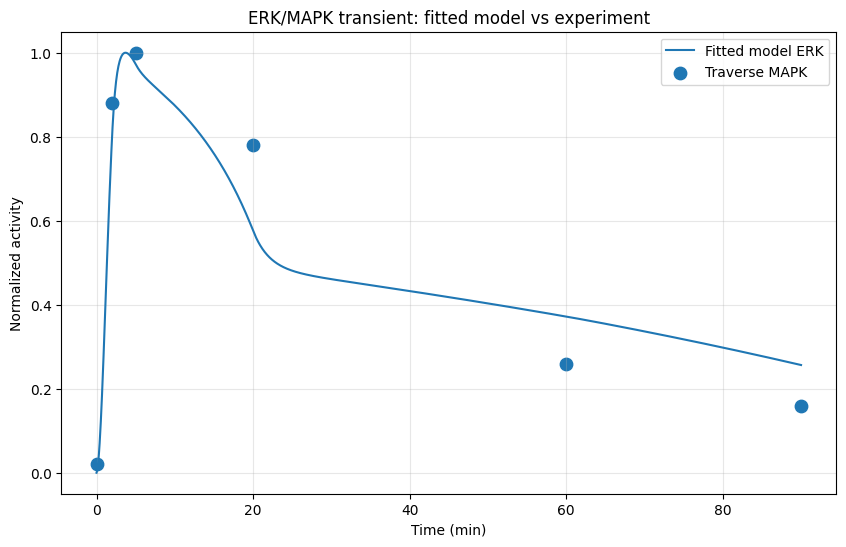

In [52]:
plt.figure(figsize=(10, 6))

plt.plot(
    t_model,
    erk_fit,
    label="Fitted model ERK"
)

plt.scatter(
    t_exp,
    mapk_exp,
    s=80,
    label="Traverse MAPK"
)

plt.xlabel("Time (min)")
plt.ylabel("Normalized activity")
plt.title("ERK/MAPK transient: fitted model vs experiment")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [57]:
erk_at_exp = np.interp(
    t_exp,
    t_model,
    erk_fit
)

residuals = erk_at_exp - mapk_exp

print("Time | Experimental | Model | Residual")
print("-" * 45)

for t, exp, model, resid in zip(
    t_exp,
    mapk_exp,
    erk_at_exp,
    residuals
):
    print(
        f"{t:4.0f} | "
        f"{exp:12.3f} | "
        f"{model:5.3f} | "
        f"{resid:+8.3f}"
    )

print("\nSSE:", np.sum(residuals**2))
print("RMSE:", np.sqrt(np.mean(residuals**2)))

peak_idx = np.argmax(erk_fit)

print("\nModel ERK peak:")
print(f"  time = {t_model[peak_idx]:.2f} min")
print(f"  value = {erk_fit[peak_idx]:.3f}")

print("\nExperimental ERK peak:")
print(f"  time = {t_exp[np.argmax(mapk_exp)]:.2f} min")
print(f"  value = {mapk_exp.max():.3f}")

Time | Experimental | Model | Residual
---------------------------------------------
   0 |        0.020 | 0.000 |   -0.020
   2 |        0.880 | 0.599 |   -0.281
   5 |        1.000 | 0.990 |   -0.010
  20 |        0.780 | 0.780 |   -0.000
  60 |        0.260 | 0.517 |   +0.257
  90 |        0.160 | 0.388 |   +0.228

SSE: 0.19796540498015405
RMSE: 0.1816431506095372

Model ERK peak:
  time = 6.55 min
  value = 1.000

Experimental ERK peak:
  time = 5.00 min
  value = 1.000


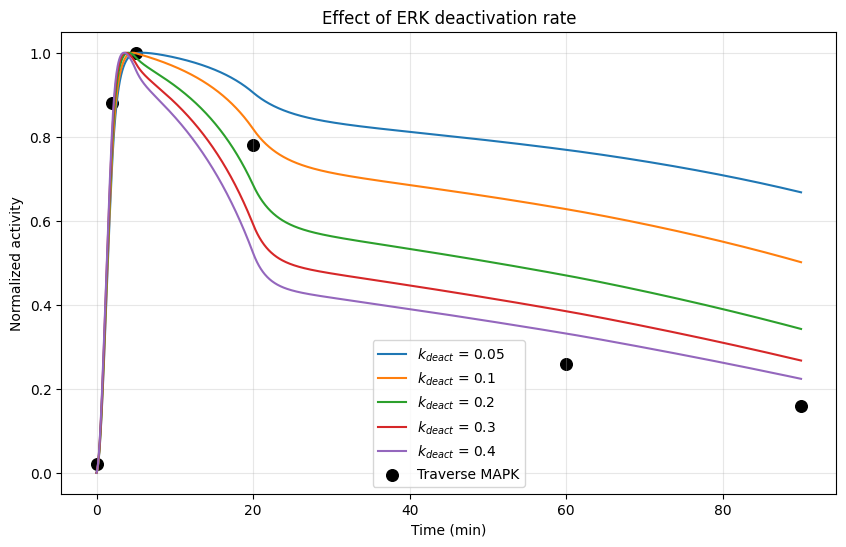

In [58]:
k_values = [0.05, 0.10, 0.20, 0.30, 0.40]

plt.figure(figsize=(10, 6))

for k_deact in k_values:

    erk_test = simulate_erk(
        1.2,
        k_deact
    )

    plt.plot(
        t_model,
        erk_test,
        label=f"$k_{{deact}}$ = {k_deact}"
    )

plt.scatter(
    t_exp,
    mapk_exp,
    s=70,
    color="black",
    label="Traverse MAPK"
)

plt.xlabel("Time (min)")
plt.ylabel("Normalized activity")
plt.title("Effect of ERK deactivation rate")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [56]:
from scipy.optimize import least_squares

# ---------------------------------------------------------
# ERK model driven by the fitted MEK trajectory
# ---------------------------------------------------------

def simulate_erk(k_erk_act, k_erk_deact):
    def erk_rhs(t, y):
        erk = y[0]

        # Interpolate fitted MEK at this time
        mek = np.interp(t, t_exp, mapkk_exp)

        derk = (
            k_erk_act * mek * (1.0 - erk)
            - k_erk_deact * erk
        )

        return [derk]

    sol_erk = solve_ivp(
        erk_rhs,
        (0, 90),
        [0.0],
        t_eval=t_model,
        rtol=1e-9,
        atol=1e-12
    )

    erk = sol_erk.y[0]

    # Normalize to model peak
    erk_norm = erk / erk.max()

    return erk_norm


# ---------------------------------------------------------
# Residual function for fitting
# ---------------------------------------------------------

def erk_residuals(log_params):

    # Fit in log-space so parameters remain positive
    k_erk_act = np.exp(log_params[0])
    k_erk_deact = np.exp(log_params[1])

    erk_model = simulate_erk(
        k_erk_act,
        k_erk_deact
    )

    # Model prediction at experimental time points
    erk_at_exp = np.interp(
        t_exp,
        t_model,
        erk_model
    )

    return erk_at_exp - mapk_exp


# ---------------------------------------------------------
# Initial guess
# ---------------------------------------------------------

initial_guess = [
    np.log(1.5),   # k_erk_act
    np.log(0.025)  # k_erk_deact
]


# ---------------------------------------------------------
# Fit
# ---------------------------------------------------------

fit = least_squares(
    erk_residuals,
    initial_guess
)

k_erk_act_fit = np.exp(fit.x[0])
k_erk_deact_fit = np.exp(fit.x[1])

print("Fitted ERK parameters:")
print(f"  k_erk_act   = {k_erk_act_fit:.6f}")
print(f"  k_erk_deact = {k_erk_deact_fit:.6f}")


# ---------------------------------------------------------
# Final fitted trajectory
# ---------------------------------------------------------

erk_fit = simulate_erk(
    k_erk_act_fit,
    k_erk_deact_fit
)

erk_at_exp = np.interp(
    t_exp,
    t_model,
    erk_fit
)

sse_erk = np.sum(
    (erk_at_exp - mapk_exp)**2
)

print("\nERK fitting SSE:")
print(f"  {sse_erk:.6f}")

Fitted ERK parameters:
  k_erk_act   = 0.684093
  k_erk_deact = 0.105911

ERK fitting SSE:
  0.197965


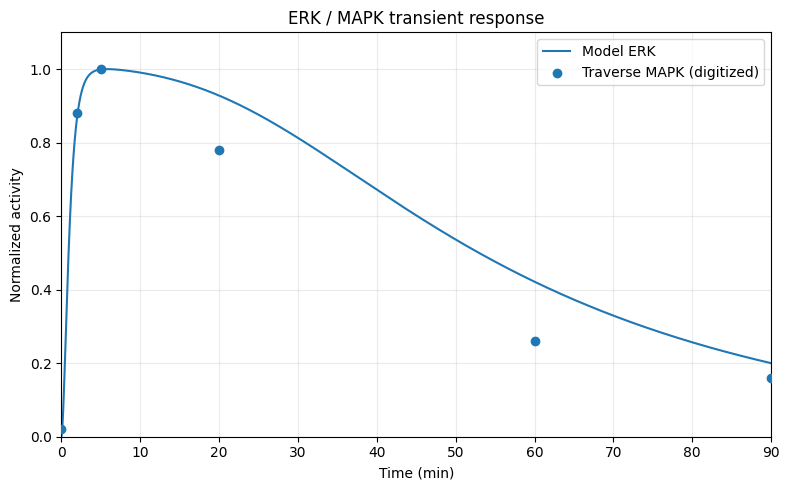

In [48]:

# ERK / MAPK comparison
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(t_model, erk_model_norm, label="Model ERK")
ax.scatter(t_exp, mapk_exp, label="Traverse MAPK (digitized)", zorder=3)

ax.set_xlabel("Time (min)")
ax.set_ylabel("Normalized activity")
ax.set_title("ERK / MAPK transient response")
ax.set_xlim(0, 90)
ax.set_ylim(0, 1.1)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()



## 3. Simple shape diagnostics

These diagnostics are **not a formal statistical fit**. They answer a narrower question:

> Does the bounded ODE produce the same broad timing and persistence pattern as the experiment?

We compare:

1. peak time,
2. activity remaining at 20 min,
3. activity remaining at 60 min,
4. activity remaining at 90 min.

Because the experimental values were manually digitized from a figure, numerical agreement should not be overinterpreted.


In [8]:

def summarize_curve(t, y_norm):
    peak_idx = np.argmax(y_norm)
    return {
        "peak_time_min": t[peak_idx],
        "at_20_min": np.interp(20, t, y_norm),
        "at_60_min": np.interp(60, t, y_norm),
        "at_90_min": np.interp(90, t, y_norm),
    }

summary = pd.DataFrame({
    "Traverse MAPKK": summarize_curve(t_exp, mapkk_exp),
    "Model MEK": summarize_curve(t_model, mek_model_norm),
    "Traverse MAPK": summarize_curve(t_exp, mapk_exp),
    "Model ERK": summarize_curve(t_model, erk_model_norm),
}).T

summary.round(3)


NameError: name 'pd' is not defined


## 4. Interpretation

### What would count as success?

For this first test, we are looking for the model to reproduce the **qualitative structure**:

- MEK/MAPKK peaks before ERK/MAPK.
- MEK/MAPKK is shorter-lived.
- ERK/MAPK peaks later and persists longer.
- Both eventually decline after the transient upstream stimulus.

If those features appear, then the bounded ODE framework is **capable of producing the correct qualitative behavior**.

### What would NOT count as validation?

This notebook does not yet establish that the model is quantitatively correct. In particular:

- the upstream \(u(t)\) is assumed rather than experimentally reconstructed;
- the parameters are trial values;
- the Traverse values are manually digitized;
- the experiment is in PC12 cells, not L858R-mutant NSCLC;
- the model contains only MEK and ERK, not the complete EGFR→RAS→RAF→MEK→ERK cascade.

### Next step

If this qualitative test works, the next step should be **parameter fitting to the digitized data**, ideally using a better digitization of the original figure and explicit parameter bounds.

If it fails, that is scientifically useful too: the mismatch tells us which part of the current bounded framework cannot reproduce the observed transient.

Most importantly, **do not copy these trial rate constants into the main Drug Diffusion model yet.** This notebook is a validation/diagnostic experiment, not the final parameterization.


BEST-FIT PARAMETERS
--------------------
k_erk_act   = 1.150884
k_erk_deact = 0.286516

FIT QUALITY
-----------
SSE  = 0.070170
RMSE = 0.108143

RESIDUAL TABLE
--------------
Time | Experimental | Model | Residual
---------------------------------------------
   0 |        0.020 | 0.000 |   -0.020
   2 |        0.880 | 0.791 |   -0.089
   5 |        1.000 | 0.978 |   -0.022
  20 |        0.780 | 0.597 |   -0.183
  60 |        0.260 | 0.387 |   +0.127
  90 |        0.160 | 0.269 |   +0.109

PEAK COMPARISON
---------------
Model peak:        3.85 min, 1.000
Experimental peak: 5.00 min, 1.000


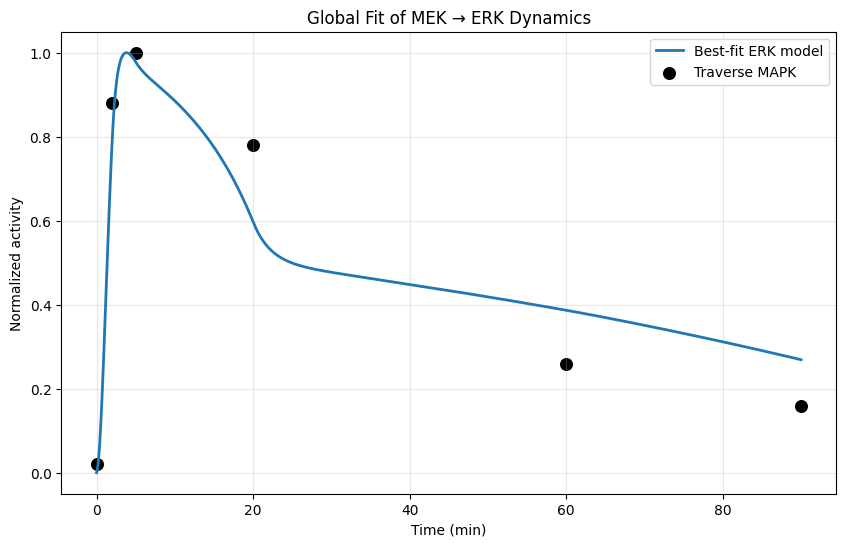

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

# ============================================================
# Experimental data (digitized approximately from Traverse et al. 1992)
# ============================================================

t_exp = np.array([0, 2, 5, 20, 60, 90], dtype=float)

mapkk_exp = np.array([0.02, 1.00, 0.63, 0.15, 0.10, 0.06], dtype=float)
mapk_exp  = np.array([0.02, 0.88, 1.00, 0.78, 0.26, 0.16], dtype=float)


# ============================================================
# Model time grid
# ============================================================

t_model = np.linspace(0, 90, 1801)


# ============================================================
# ERK model
# Uses EXPERIMENTAL MAPKK as the upstream input
# ============================================================

def simulate_erk(k_erk_act, k_erk_deact):

    def rhs(t, y):

        erk = y[0]

        # Interpolate experimental MAPKK activity
        mek = np.interp(t, t_exp, mapkk_exp)

        d_erk = (
            k_erk_act * mek * (1.0 - erk)
            - k_erk_deact * erk
        )

        return [d_erk]

    sol = solve_ivp(
        rhs,
        (t_model[0], t_model[-1]),
        [0.0],
        t_eval=t_model,
        rtol=1e-9,
        atol=1e-12
    )

    erk = sol.y[0]

    # Normalize model to its own peak,
    # matching the independently normalized experimental curve
    erk_norm = erk / np.max(erk)

    return erk_norm


# ============================================================
# Residual function for GLOBAL fit
# ============================================================

def residuals(params):

    k_erk_act, k_erk_deact = params

    erk_model = simulate_erk(
        k_erk_act,
        k_erk_deact
    )

    # Evaluate model exactly at experimental time points
    erk_at_exp = np.interp(
        t_exp,
        t_model,
        erk_model
    )

    return erk_at_exp - mapk_exp


# ============================================================
# Global nonlinear least-squares fit
# ============================================================

initial_guess = [1.0, 0.2]

fit = least_squares(
    residuals,
    x0=initial_guess,
    bounds=([1e-8, 1e-8], [100.0, 10.0]),
    xtol=1e-12,
    ftol=1e-12,
    gtol=1e-12,
    max_nfev=5000
)

k_erk_act_best = fit.x[0]
k_erk_deact_best = fit.x[1]

print("BEST-FIT PARAMETERS")
print("--------------------")
print(f"k_erk_act   = {k_erk_act_best:.6f}")
print(f"k_erk_deact = {k_erk_deact_best:.6f}")


# ============================================================
# Generate trajectory using EXACT best-fit parameters
# ============================================================

erk_best = simulate_erk(
    k_erk_act_best,
    k_erk_deact_best
)

erk_at_exp = np.interp(
    t_exp,
    t_model,
    erk_best
)

residual = erk_at_exp - mapk_exp

SSE = np.sum(residual**2)
RMSE = np.sqrt(np.mean(residual**2))

print("\nFIT QUALITY")
print("-----------")
print(f"SSE  = {SSE:.6f}")
print(f"RMSE = {RMSE:.6f}")


# ============================================================
# Residual table
# ============================================================

print("\nRESIDUAL TABLE")
print("--------------")
print("Time | Experimental | Model | Residual")
print("---------------------------------------------")

for t, exp, model, res in zip(
    t_exp,
    mapk_exp,
    erk_at_exp,
    residual
):
    print(
        f"{t:4.0f} | "
        f"{exp:12.3f} | "
        f"{model:5.3f} | "
        f"{res:+8.3f}"
    )


# ============================================================
# Peak comparison
# ============================================================

peak_index = np.argmax(erk_best)

model_peak_time = t_model[peak_index]
model_peak_value = erk_best[peak_index]

experimental_peak_index = np.argmax(mapk_exp)

experimental_peak_time = t_exp[experimental_peak_index]
experimental_peak_value = mapk_exp[experimental_peak_index]

print("\nPEAK COMPARISON")
print("---------------")
print(
    f"Model peak:        "
    f"{model_peak_time:.2f} min, "
    f"{model_peak_value:.3f}"
)

print(
    f"Experimental peak: "
    f"{experimental_peak_time:.2f} min, "
    f"{experimental_peak_value:.3f}"
)


# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    t_model,
    erk_best,
    label="Best-fit ERK model",
    linewidth=2
)

plt.scatter(
    t_exp,
    mapk_exp,
    s=70,
    color="black",
    label="Traverse MAPK"
)

plt.xlabel("Time (min)")
plt.ylabel("Normalized activity")
plt.title("Global Fit of MEK → ERK Dynamics")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [60]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

# ============================================================
# Experimental MAPKK data
# ============================================================

t_exp = np.array([0, 2, 5, 20, 60, 90], dtype=float)

mapkk_exp = np.array([
    0.02,
    1.00,
    0.63,
    0.15,
    0.10,
    0.06
], dtype=float)


# ============================================================
# Model time grid
# ============================================================

t_model = np.linspace(0, 90, 1801)


# ============================================================
# Effective upstream input
# ============================================================

def transient_input(t, tau_u):
    return np.exp(-t / tau_u)


# ============================================================
# MEK model
# ============================================================

def simulate_mek(k_mek_act, k_mek_deact, tau_u):

    def rhs(t, y):

        mek = y[0]
        u = transient_input(t, tau_u)

        d_mek = (
            k_mek_act * u * (1.0 - mek)
            - k_mek_deact * mek
        )

        return [d_mek]

    sol = solve_ivp(
        rhs,
        (t_model[0], t_model[-1]),
        [0.0],
        t_eval=t_model,
        rtol=1e-9,
        atol=1e-12
    )

    mek = sol.y[0]

    # Normalize to model peak because experimental
    # MAPKK data were also independently normalized
    mek_norm = mek / np.max(mek)

    return mek_norm


# ============================================================
# Residual function
# ============================================================

def mek_residuals(params):

    k_mek_act, k_mek_deact, tau_u = params

    mek_model = simulate_mek(
        k_mek_act,
        k_mek_deact,
        tau_u
    )

    mek_at_exp = np.interp(
        t_exp,
        t_model,
        mek_model
    )

    return mek_at_exp - mapkk_exp


# ============================================================
# Global nonlinear least-squares fit
# ============================================================

initial_guess = [
    40.0,   # k_mek_act
    0.13,   # k_mek_deact
    0.18    # tau_u
]

fit_mek = least_squares(
    mek_residuals,
    x0=initial_guess,
    bounds=(
        [1e-8, 1e-8, 1e-4],
        [1000.0, 10.0, 100.0]
    ),
    xtol=1e-12,
    ftol=1e-12,
    gtol=1e-12,
    max_nfev=5000
)

k_mek_act_best = fit_mek.x[0]
k_mek_deact_best = fit_mek.x[1]
tau_u_best = fit_mek.x[2]

print("BEST-FIT PARAMETERS")
print("--------------------")
print(f"k_mek_act   = {k_mek_act_best:.6f}")
print(f"k_mek_deact = {k_mek_deact_best:.6f}")
print(f"tau_u       = {tau_u_best:.6f} min")


# ============================================================
# Generate trajectory using EXACT best-fit parameters
# ============================================================

mek_best = simulate_mek(
    k_mek_act_best,
    k_mek_deact_best,
    tau_u_best
)

mek_at_exp = np.interp(
    t_exp,
    t_model,
    mek_best
)

residual = mek_at_exp - mapkk_exp


# ============================================================
# Fit quality
# ============================================================

SSE = np.sum(residual**2)
RMSE = np.sqrt(np.mean(residual**2))

print("\nFIT QUALITY")
print("-----------")
print(f"SSE  = {SSE:.6f}")
print(f"RMSE = {RMSE:.6f}")


# ============================================================
# Residual table
# ============================================================

print("\nRESIDUAL TABLE")
print("--------------")
print("Time | Experimental | Model | Residual")
print("---------------------------------------------")

for t, exp, model, res in zip(
    t_exp,
    mapkk_exp,
    mek_at_exp,
    residual
):
    print(
        f"{t:4.0f} | "
        f"{exp:12.3f} | "
        f"{model:5.3f} | "
        f"{res:+8.3f}"
    )


# ============================================================
# Peak comparison
# ============================================================

model_peak_index = np.argmax(mek_best)

model_peak_time = t_model[model_peak_index]
model_peak_value = mek_best[model_peak_index]

experimental_peak_index = np.argmax(mapkk_exp)

experimental_peak_time = t_exp[experimental_peak_index]
experimental_peak_value = mapkk_exp[experimental_peak_index]

print("\nPEAK COMPARISON")
print("---------------")
print(
    f"Model peak:        "
    f"{model_peak_time:.2f} min, "
    f"{model_peak_value:.3f}"
)

print(
    f"Experimental peak: "
    f"{experimental_peak_time:.2f} min, "
    f"{experimental_peak_value:.3f}"
)

BEST-FIT PARAMETERS
--------------------
k_mek_act   = 1000.000000
k_mek_deact = 0.119590
tau_u       = 0.276590 min

FIT QUALITY
-----------
SSE  = 0.019601
RMSE = 0.057156

RESIDUAL TABLE
--------------
Time | Experimental | Model | Residual
---------------------------------------------
   0 |        0.020 | 0.000 |   -0.020
   2 |        1.000 | 0.952 |   -0.048
   5 |        0.630 | 0.676 |   +0.046
  20 |        0.150 | 0.112 |   -0.038
  60 |        0.100 | 0.001 |   -0.099
  90 |        0.060 | 0.000 |   -0.060

PEAK COMPARISON
---------------
Model peak:        0.05 min, 1.000
Experimental peak: 2.00 min, 1.000
